# 04. Thời gian thanh toán (SQ3)

Khóa luận: *Ứng dụng Process Mining và học máy trong kiểm tra tuân thủ và cảnh báo sớm sai lệch quy trình Mua hàng - Thanh toán trên ERP SAP: Nghiên cứu dữ liệu BPI Challenge 2019.* Người thực hiện: Trần Xuân Ái.

Notebook này tái tạo kết quả SQ3 (Mục 4.3) theo thiết kế ở Mục 3.7.3, dùng các hàm của `src/sq3_thoi_gian.py`:

1. Mô tả: Kaplan-Meier toàn bộ và theo nhánh, thời gian chờ theo giai đoạn, thứ trong tuần của thanh toán
2. Thời điểm dấu hiệu so với thời gian theo dõi
3. Hồi quy Cox có biến thay đổi theo thời gian (R2a, R3, làm lại) và biến ban đầu (R6, biến thể phụ của R7), có biến kiểm soát
4. Phân tích mốc ngày 30, log-rank, kiểm tra giả định nguy cơ tỷ lệ (Schoenfeld) và RMST đến 180 ngày
5. Ba phân tích độ nhạy
6. Kiểm tra cơ chế: từ dấu hiệu đến thanh toán, chỉ báo làm lại và định nghĩa trạng thái, mốc thời gian của biến thể phụ R7 (dùng `sq3_kiem_tra_co_che.py`)

Thời gian thanh toán = Create Purchase Order Item đầu tiên → Clear Invoice "thanh toán" cuối cùng, tính theo ngày nguyên (làm tròn lên). Dòng hàng còn mở bị kiểm duyệt tại thời điểm trích xuất; dòng hàng bị xóa bị loại. HR < 1 nghĩa là thanh toán chậm hơn. Mọi kết quả là mối liên hệ, không phải quan hệ nhân quả.

Cần thư viện `lifelines` (`python -m pip install lifelines`). Bước 3 và bước 5 chạy lâu nhất (mỗi mô hình vài phút).

**Cách chạy.** Mở notebook từ thư mục gốc `ma_nguon_kltn` (các module nằm trong `src/`). Đường dẫn log lấy từ `src/cau_hinh.py`: mặc định `du_lieu/BPI_Challenge_2019.xes`, hoặc đặt biến môi trường `KLTN_LOG`. Chọn *Run All*.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.dont_write_bytecode = True  # không tạo src/__pycache__
sys.path.insert(0, str(Path("src").resolve()))  # các module nằm trong src/
import cau_hinh

import sq2_tuan_thu as sq2
import sq3_kiem_tra_co_che as co_che
import sq3_thoi_gian as sq3
from r5_v2_phan_loai_clear import buoc2_moc_trich_xuat, loc_pham_vi, sap_xep

LOG = str(cau_hinh.LOG)
CONG_TY = "companyID_0000"
RA = Path("ket_qua_04_thoi_gian")
RA.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
vn = sq3.vn
nhat_ky = []


def p(*x):
    s = " ".join(str(i) for i in x)
    print(s)
    nhat_ky.append(s)


def bang_hr(hr, mo_hinh, luat=sq3.LUAT_SQ3):
    # Bảng HR của các luật trong một mô hình, định dạng kiểu Việt Nam.
    h = hr[hr["mo_hinh"] == mo_hinh].set_index("bien").reindex(luat)
    out = pd.DataFrame(index=[sq3.TEN.get(l, l) for l in luat])
    out["HR"] = [sq3.so(v, 3) for v in h["HR"]]
    out["KTC 95%"] = [f"{sq3.so(a, 3)}–{sq3.so(b, 3)}" for a, b in zip(h["KTC_duoi"], h["KTC_tren"])]
    out["p"] = [sq3.so_p(v) for v in h["p"]]
    if "p_holm" in h:
        out["p Holm"] = [sq3.so_p(v) for v in h["p_holm"]]
    return out

## 0. Đọc nhật ký và chuẩn bị bảng dòng hàng

Dùng đúng các bước tiền xử lý của Chương 3 (thời điểm trích xuất, phễu lọc, Δ = 60 phút, trạng thái theo định nghĩa cuối). Số dòng hàng theo luật được đối chiếu với kiểm chứng cuối; thời gian thanh toán được đối chiếu với Mục 3.2.2.

In [2]:
t0 = time.time()
raw = sq2.doc_log(LOG)
moc, _, _ = buoc2_moc_trich_xuat(raw, None)
pv = loc_pham_vi(raw, CONG_TY, moc)
ev = sap_xep(raw[raw["case"].isin(pv)])
del raw
p(f"Đọc log xong sau {time.time() - t0:,.0f} giây. Phạm vi {vn(len(pv))} dòng hàng, {vn(len(ev))} sự kiện; trích xuất {moc}.")

d, thu, top = sq3.chuan_bi(ev, pv, moc, p)
x, loai = sq3.tap_phan_tich(d, "tt_moi", moc)
ks_all, ten_hm = sq3.bien_kiem_soat(d, top)
p(f"Tập phân tích: {vn(len(x))} dòng hàng (hoàn tất {vn(int(x['E'].sum()))}, còn mở bị kiểm duyệt "
  f"{vn(int((x['E'] == 0).sum()))}); loại " + ", ".join(f"{k} {vn(v)}" for k, v in loai.items()) + ".")
display(pd.Series(ten_hm, name="hạng mục chi tiêu").to_frame().assign(**{"tham chiếu": str(top[0])}))

Đọc log xong sau 81 giây. Phạm vi 210.887 dòng hàng, 1.175.650 sự kiện; trích xuất 2019-01-18 13:34:00.


Log đang ở UTC (Vendor creates invoice lúc 21:59/22:59: 100.0%). Đổi sang Europe/Amsterdam cho phân tích theo giờ/thứ.


  Sau khi đổi: Vendor creates invoice lúc 23:59 giờ địa phương: 100.0%
  Thứ tự sự kiện và khoảng cách thời gian không đổi; mọi luật vẫn tính trên timestamp gốc.


Số dòng hàng theo luật khớp kiểm chứng (R2a 508, R3 2.008, R6 650, R7b 2.430, làm lại 2.982).
Mọi dòng hàng bị đánh dấu đều có thời điểm dấu hiệu.


Tập phân tích: 203.607 dòng hàng (hoàn tất 163.619, còn mở bị kiểm duyệt 39.988); loại bị xóa 7.280, thời gian ≤ 0 hoặc thiếu 0.


,hạng mục chi tiêu,tham chiếu
hm_1,Sales,Packaging
hm_2,Trading & End Products,Packaging
hm_3,Additives,Packaging
hm_4,CAPEX & SOCS,Packaging
hm_5,Latex & Monomers,Packaging
hm_6,(không ghi hạng mục),Packaging
hm_7,Pigments & Colorants,Packaging
hm_khac,Khác,Packaging


## 1. Mô tả thời gian thanh toán

Đường Kaplan-Meier là tỷ lệ dòng hàng đã thanh toán xong theo số ngày kể từ khi tạo dòng đơn hàng. Thanh toán chạy theo đợt hằng tuần, nên chênh lệch dưới một tuần không được diễn giải.


=== 1. Mô tả ===


Kiểm tra với Mục 3.2.2 (số ngày thực): hoàn tất 163.619, còn mở 39.988; trung vị 77,4, P90 127,2, trung vị Kaplan-Meier 84,6 ngày (kỳ vọng 163.619; 39.988; 77,4; 127,2; 84,6).


Trên thang ngày nguyên: trung vị Kaplan-Meier 85 ngày, P90 Kaplan-Meier 141 ngày.
Tỷ lệ đã thanh toán xong (Kaplan-Meier): ngày 30: 6,0%; ngày 60: 27,2%; ngày 90: 54,2%; ngày 120: 78,6%; ngày 180: 94,2%; ngày 365: 96,3%
Dòng hoàn tất: đến Clear thanh toán đầu tiên trung vị 77,1 ngày, đến Clear thanh toán cuối cùng 77,4 ngày; 3.262 (1,99%) dòng có hơn một thời điểm thanh toán.

Theo nhánh:
  nhánh (a): 175.933 dòng, hoàn tất 149.362 (84,90%); trung vị KM 84, P90 KM 136 ngày; trung vị dòng hoàn tất 77,7 ngày


  nhánh (b): 15.293 dòng, hoàn tất 13.710 (89,65%); trung vị KM 83, P90 KM 133 ngày; trung vị dòng hoàn tất 77,2 ngày
  nhánh khác: 12.381 dòng, hoàn tất 547 (4,42%); trung vị KM –, P90 KM – ngày; trung vị dòng hoàn tất 53,0 ngày

Thời gian chờ theo giai đoạn, dòng hoàn tất (ngày; trung vị [P25–P75]):
  (a) tạo đơn hàng → nhận hàng đầu tiên: n = 149.362; 8,5 [4,4–16,8]
  (a) ghi nhận hóa đơn đầu tiên → gỡ khóa đầu tiên: n = 32.058; 10,3 [3,8–38,1]
  (a) gỡ khóa đầu tiên → thanh toán cuối cùng: n = 32.058; 22,7 [6,6–51,3]; âm 7
  (a) ghi nhận hóa đơn đầu tiên → thanh toán cuối cùng: n = 149.362; 42,9 [22,9–71,1]
  (b) tạo đơn hàng → nhận hàng đầu tiên: n = 13.710; 13,9 [6,4–21,0]
  (b) ghi nhận hóa đơn đầu tiên → gỡ khóa đầu tiên: n = 13.464; 2,5 [1,0–5,3]


  (b) gỡ khóa đầu tiên → thanh toán cuối cùng: n = 13.464; 51,3 [21,4–83,4]; âm 5
  (b) ghi nhận hóa đơn đầu tiên → thanh toán cuối cùng: n = 13.710; 59,0 [29,1–92,3]

Clear Invoice thanh toán theo thứ (giờ địa phương): Thứ Hai 283 (0,2%); Thứ Ba 1.832 (1,1%); Thứ Tư 5.493 (3,2%); Thứ Năm 130.861 (76,5%); Thứ Sáu 32.522 (19,0%); Thứ Bảy 56 (0,0%); Chủ nhật 93 (0,1%)


,nhanh,so_dong,hoan_tat,trung_vi_km,p90_km,trung_vi_hoan_tat
0,(a),175933,149362,84.0,136.0,77.7
1,(b),15293,13710,83.0,133.0,77.2
2,khác,12381,547,NaN,NaN,53.0


,nhanh,giai_doan,n,trung_vi,p25,p75,so_am
0,(a),tạo đơn hàng → nhận hàng đầu tiên,149362,8.5,4.4,16.8,0
1,(a),ghi nhận hóa đơn đầu tiên → gỡ khóa đầu tiên,32058,10.3,3.8,38.1,0
2,(a),gỡ khóa đầu tiên → thanh toán cuối cùng,32058,22.7,6.6,51.3,7
3,(a),ghi nhận hóa đơn đầu tiên → thanh toán cuối cùng,149362,42.9,22.9,71.1,0
4,(b),tạo đơn hàng → nhận hàng đầu tiên,13710,13.9,6.4,21.0,0
5,(b),ghi nhận hóa đơn đầu tiên → gỡ khóa đầu tiên,13464,2.5,1.0,5.3,0
6,(b),gỡ khóa đầu tiên → thanh toán cuối cùng,13464,51.3,21.4,83.4,5
7,(b),ghi nhận hóa đơn đầu tiên → thanh toán cuối cùng,13710,59.0,29.1,92.3,0


Đã vẽ km_toan_bo_theo_nhanh.png, km_minh_hoa_theo_luat.png.


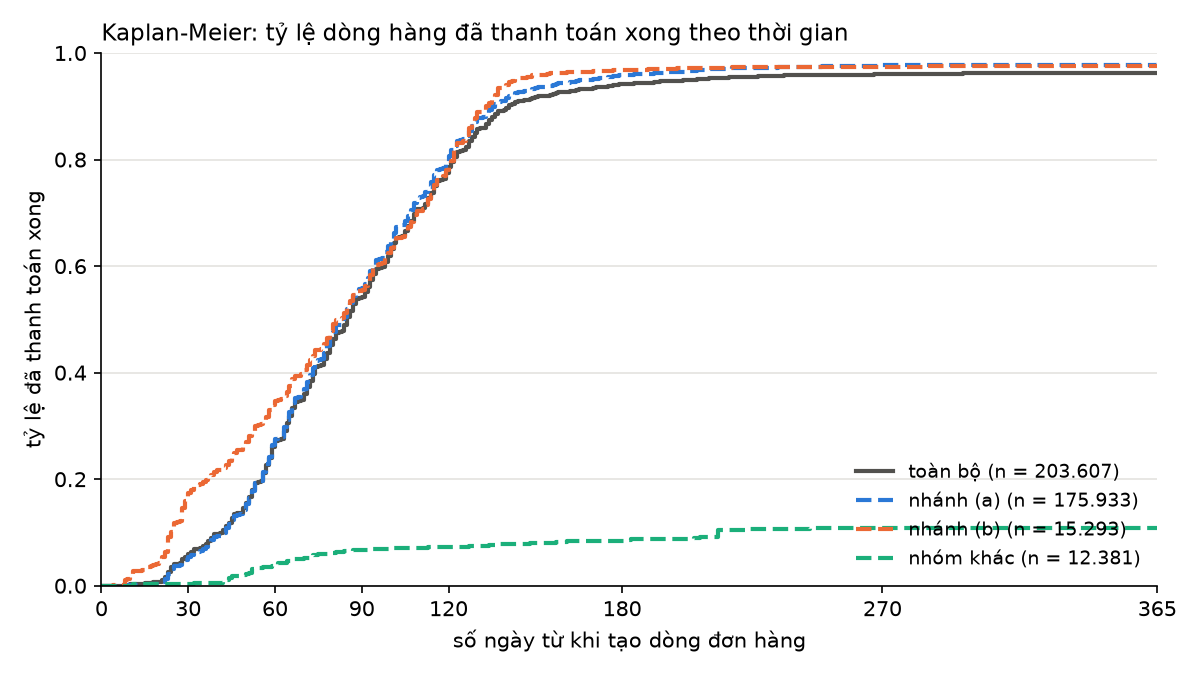

In [3]:
sq3.mo_ta(d, x, thu, moc, RA, p)
display(pd.read_csv(RA / "km_theo_nhanh.csv").round(1))
display(pd.read_csv(RA / "cho_theo_giai_doan.csv").round(1))
sq3.ve_hinh(x, None, RA, p)
display(Image(filename=str(RA / "km_toan_bo_theo_nhanh.png")))

## 2. Thời điểm dấu hiệu so với thời gian theo dõi

Dấu hiệu xảy ra giữa chừng là lý do không được so sánh theo nhóm cuối cùng (thiên lệch thời gian bất tử). Dấu hiệu xảy ra sau khi đã thanh toán xong không làm dòng hàng phơi nhiễm trong thời gian theo dõi. Hình dưới chỉ để minh họa, không dùng để kiểm định.


Thời điểm dấu hiệu so với thời gian theo dõi (tập phân tích):
  R2a: 504 dòng; dấu hiệu sau trung vị 24,9 ngày; phơi nhiễm từ ngày đầu 0, giữa chừng 504, sau thanh toán/kiểm duyệt 0
  R3: 2.008 dòng; dấu hiệu sau trung vị 47,1 ngày; phơi nhiễm từ ngày đầu 0, giữa chừng 1.973, sau thanh toán/kiểm duyệt 35
  Làm lại: 2.982 dòng; dấu hiệu sau trung vị 83,0 ngày; phơi nhiễm từ ngày đầu 0, giữa chừng 2.978, sau thanh toán/kiểm duyệt 4
  R6 (nhận hàng do người tạo đơn): 648 dòng; dấu hiệu sau trung vị 20,2 ngày; phơi nhiễm từ ngày đầu 120, giữa chừng 527, sau thanh toán/kiểm duyệt 1


,co_dau_hieu,phoi_nhiem_tu_dau,phoi_nhiem_giua_chung,sau_khi_ket_thuc,truoc_tao_don,trung_vi_ngay
luat,,,,,,
R2a,504,0,504,0,0,24.9
R3,2008,0,1973,35,0,47.1
lam_lai,2982,0,2978,4,0,83.0
R6,648,120,527,1,0,20.2


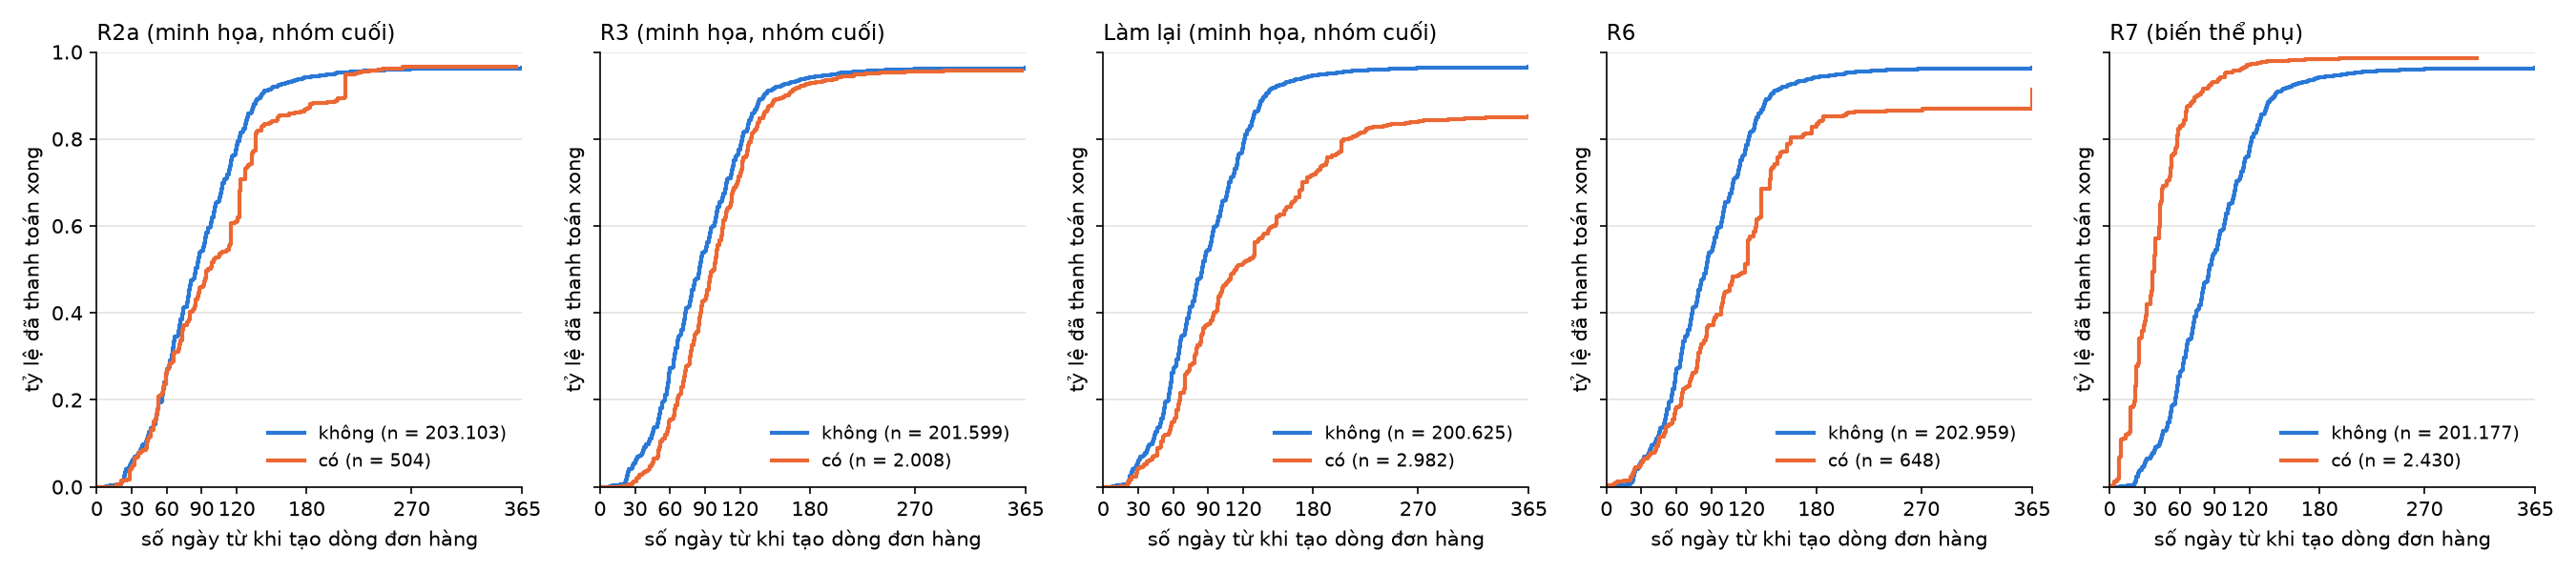

In [4]:
display(sq3.dem_phoi_nhiem(x, p).set_index("luat").round(1))
display(Image(filename=str(RA / "km_minh_hoa_theo_luat.png")))

## 3. Hồi quy Cox có biến thay đổi theo thời gian

R2a, R3 và làm lại là biến thay đổi theo thời gian (bằng 0 trước và 1 sau dấu hiệu đầu tiên); R6 và biến thể phụ của R7 là biến ban đầu. Biến kiểm soát: nhánh, hạng mục chi tiêu, nhiều lần nhận hàng hoặc ghi nhận hóa đơn, log giá trị (kèm chỉ báo giá trị 0), log quy mô nhà cung cấp. Giá trị p của 5 luật được hiệu chỉnh theo Holm. Kiểm tra độ vững: R6 thay đổi theo thời gian tại lần nhận hàng do chính người tạo dòng đơn hàng thực hiện.

In [5]:
hr = sq3.buoc_cox(x, ks_all, ten_hm, RA, p)
display(bang_hr(hr, "chinh"))
display(bang_hr(hr, "R6_thay_doi_theo_thoi_gian", ["R6_tv"]))


=== 2. Cox có biến thay đổi theo thời gian (R2a, R3, làm lại) và biến ban đầu (R6, R7b), có biến kiểm soát ===
HR < 1: thanh toán chậm hơn; HR > 1: nhanh hơn.


209.023 đoạn thời gian; 163.619 sự kiện; chạy 51 giây.
  R2a                      HR 1,278 (KTC 95%: 1,165–1,403); p < 0,001; p Holm < 0,001
  R3                       HR 1,438 (KTC 95%: 1,373–1,506); p < 0,001; p Holm < 0,001
  Làm lại                  HR 4,842 (KTC 95%: 4,604–5,091); p < 0,001; p Holm < 0,001
  R6                       HR 0,524 (KTC 95%: 0,478–0,573); p < 0,001; p Holm < 0,001
  R7 (biến thể phụ)        HR 4,600 (KTC 95%: 4,413–4,795); p < 0,001; p Holm < 0,001
Biến kiểm soát:
  nhanh_b                  HR 1,166 (KTC 95%: 1,145–1,187); p < 0,001
  nhanh_khac               HR 0,030 (KTC 95%: 0,028–0,033); p < 0,001
  Sales                    HR 2,822 (KTC 95%: 2,785–2,860); p < 0,001
  Trading & End Products   HR 1,656 (KTC 95%: 1,622–1,689); p < 0,001
  Additives                HR 1,541 (KTC 95%: 1,506–1,576); p < 0,001
  CAPEX & SOCS             HR 6,174 (KTC 95%: 5,973–6,382); p < 0,001
  Latex & Monomers         HR 2,093 (KTC 95%: 2,008–2,181); p < 0,001
  (không 

  R6 (thay đổi theo t.g.)  HR 0,581 (KTC 95%: 0,531–0,636); p < 0,001


,HR,KTC 95%,p,p Holm
R2a,"1,278","1,165–1,403","< 0,001","< 0,001"
R3,"1,438","1,373–1,506","< 0,001","< 0,001"
Làm lại,"4,842","4,604–5,091","< 0,001","< 0,001"
R6,"0,524","0,478–0,573","< 0,001","< 0,001"
R7 (biến thể phụ),"4,600","4,413–4,795","< 0,001","< 0,001"


,HR,KTC 95%,p,p Holm
R6 (thay đổi theo thời gian),"0,581","0,531–0,636","< 0,001",–


## 4. Mốc ngày 30, log-rank, giả định nguy cơ tỷ lệ và RMST

R2a, R3, làm lại: chỉ giữ dòng hàng chưa thanh toán xong và chưa bị kiểm duyệt sau ngày 30, chia nhóm theo dấu hiệu đã xảy ra đến ngày 30. R6 và biến thể phụ của R7: toàn bộ dòng hàng. RMST là số ngày trung bình chưa thanh toán xong trong 180 ngày đầu (tập mốc: 150 ngày sau ngày 30); chênh lệch dương nghĩa là dòng hàng có dấu hiệu thanh toán chậm hơn. RMST được dùng thay HR khi kiểm định Schoenfeld bác bỏ giả định nguy cơ tỷ lệ.


=== 3. Mốc ngày 30, log-rank, giả định nguy cơ tỷ lệ, RMST ===
Tập mốc: 189.663 (93,15%) dòng hàng chưa thanh toán xong và chưa bị kiểm duyệt sau ngày 30.


R2a (mốc ngày 30): có 271, không 189.392; trung vị KM 75 so với 58 ngày; log-rank χ² = 3,0, p Holm 0,083; HR Cox 1,169 (1,032–1,325)
    Schoenfeld χ² = 28,8, p < 0,001 → vi phạm, báo cáo RMST; RMST đến 150 ngày: 66,3 so với 63,8, chênh 2,5 ngày (KTC 95%: -2,3–7,3); chênh > 0 nghĩa là chậm hơn
R3 (mốc ngày 30): có 521, không 189.142; trung vị KM 49 so với 58 ngày; log-rank χ² = 56,3, p Holm < 0,001; HR Cox 1,508 (1,379–1,648)
    Schoenfeld χ² = 17,2, p < 0,001 → vi phạm, báo cáo RMST; RMST đến 150 ngày: 51,4 so với 63,8, chênh -12,5 ngày (KTC 95%: -15,4–-9,6); chênh > 0 nghĩa là chậm hơn
Làm lại (mốc ngày 30): có 262, không 189.401; trung vị KM 28 so với 58 ngày; log-rank χ² = 216,1, p Holm < 0,001; HR Cox 6,770 (5,945–7,709)
    Schoenfeld χ² = 0,8, p 0,367; RMST đến 150 ngày: 34,6 so với 63,8, chênh -29,3 ngày (KTC 95%: -32,9–-25,6); chênh > 0 nghĩa là chậm hơn
R6 (toàn bộ): có 648, không 202.959; trung vị KM 119 so với 85 ngày; log-rank χ² = 144,1, p Holm < 0,001; HR Cox 0,574 (0,5

Đã vẽ km_toan_bo_theo_nhanh.png, km_minh_hoa_theo_luat.png, km_moc_ngay_30.png.


,luat,tap,n_co,n_khong,trung_vi_co,trung_vi_khong,log_rank_p_holm,cox_HR,schoenfeld_p,rmst_co,rmst_khong,rmst_chenh,rmst_duoi,rmst_tren
0,R2a,mốc ngày 30,271,189392,75.0,58.0,0.083,1.169,0.000,66.284,63.795,2.489,-2.319,7.297
1,R3,mốc ngày 30,521,189142,49.0,58.0,0.000,1.508,0.000,51.356,63.836,-12.481,-15.403,-9.559
2,lam_lai,mốc ngày 30,262,189401,28.0,58.0,0.000,6.770,0.367,34.581,63.840,-29.258,-32.946,-25.570
3,R6,toàn bộ,648,202959,119.0,85.0,0.000,0.574,0.000,110.727,89.556,21.171,17.285,25.058
4,R7b,toàn bộ,2430,201177,38.0,86.0,0.000,4.488,0.000,42.838,90.200,-47.362,-48.626,-46.098


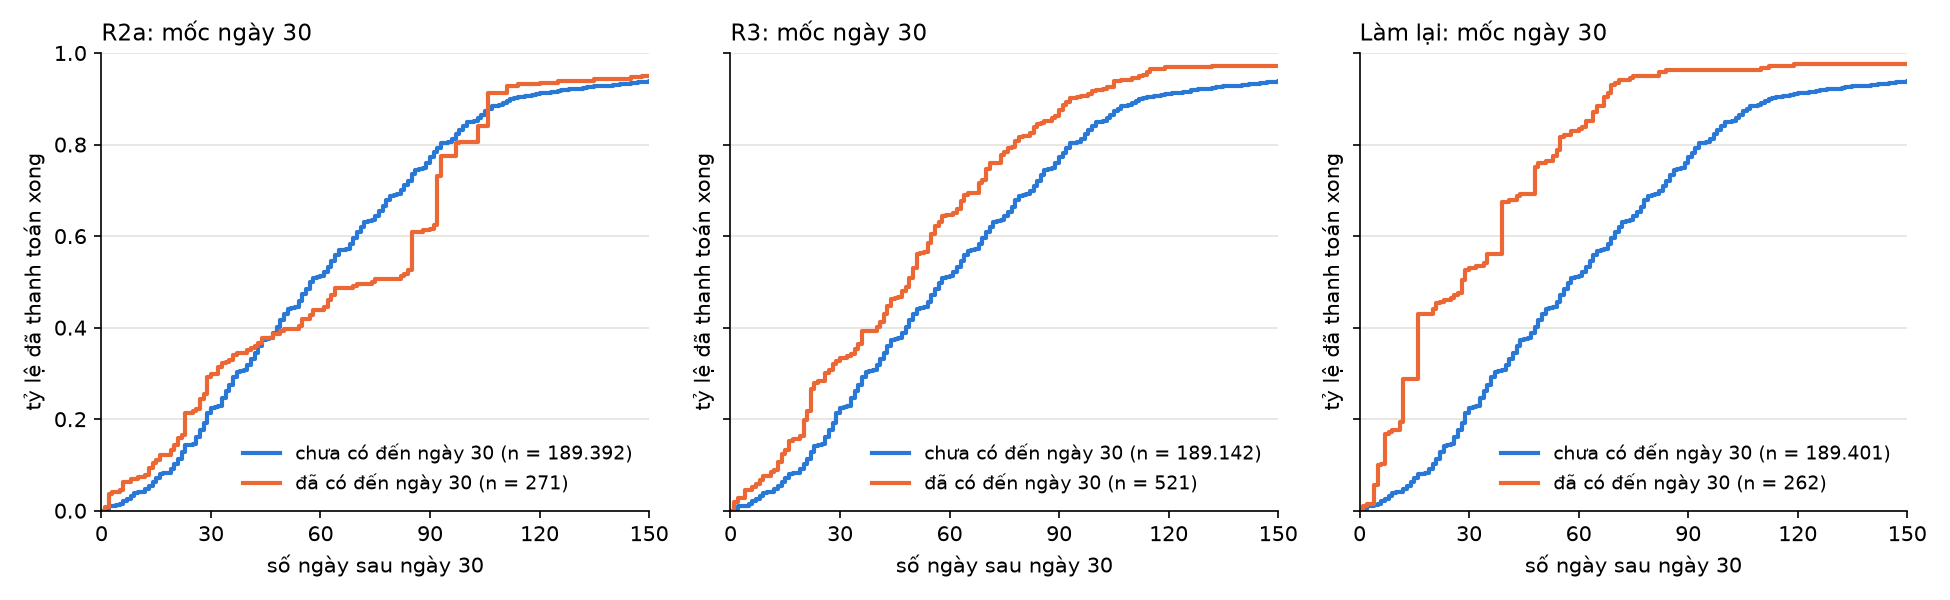

In [6]:
ss, hl, lm = sq3.buoc_moc(x, ks_all, RA, p)
sq3.ve_hinh(x, lm, RA, p)
cot = ["luat", "tap", "n_co", "n_khong", "trung_vi_co", "trung_vi_khong", "log_rank_p_holm", "cox_HR",
       "schoenfeld_p", "rmst_co", "rmst_khong", "rmst_chenh", "rmst_duoi", "rmst_tren"]
display(ss[cot].round(3))
display(Image(filename=str(RA / "km_moc_ngay_30.png")))

## 5. Độ nhạy

(1) Trạng thái hoàn tất theo định nghĩa có tính debit memo; (2) loại dòng hàng còn mở không có hoạt động trong 180 ngày trước thời điểm trích xuất; (3) loại dòng hàng có Cancel Invoice Receipt hoặc Cancel Goods Receipt (khi đó chỉ báo làm lại không còn dòng nào nên không ước lượng được).

In [7]:
hr_dn = sq3.buoc_do_nhay(d, x, ks_all, moc, RA, p)
tong = pd.concat([hr, hr_dn])
tong = tong.assign(bien=tong["bien"].replace("R6_tv", "R6"))
tong = tong[tong["bien"].isin(sq3.LUAT_SQ3)]
bang = tong.assign(o=[f"{sq3.so(h, 2)} ({sq3.so(a, 2)}–{sq3.so(b, 2)})" for h, a, b in
                      zip(tong["HR"], tong["KTC_duoi"], tong["KTC_tren"])])
thu_tu = ["chinh", "R6_thay_doi_theo_thoi_gian", "do_nhay_1_debit_memo", "do_nhay_2_khong_hoat_dong", "do_nhay_3_khong_huy"]
display(bang.pivot(index="bien", columns="mo_hinh", values="o").reindex(index=sq3.LUAT_SQ3, columns=thu_tu).fillna("–"))


=== 4. Độ nhạy (mô hình Cox có biến thay đổi theo thời gian, cùng biến kiểm soát) ===


(1) trạng thái theo định nghĩa có debit memo: 203.607 dòng, hoàn tất 162.015
  R2a                      HR 1,612 (KTC 95%: 1,469–1,769); p < 0,001
  R3                       HR 1,440 (KTC 95%: 1,374–1,509); p < 0,001
  Làm lại                  HR 0,627 (KTC 95%: 0,586–0,671); p < 0,001
  R6                       HR 0,606 (KTC 95%: 0,554–0,664); p < 0,001
  R7 (biến thể phụ)        HR 4,499 (KTC 95%: 4,315–4,691); p < 0,001


(2) loại 1.754 dòng còn mở không hoạt động > 180 ngày: 201.853 dòng, hoàn tất 163.619
  R2a                      HR 1,244 (KTC 95%: 1,133–1,365); p < 0,001
  R3                       HR 1,444 (KTC 95%: 1,379–1,512); p < 0,001
  Làm lại                  HR 4,639 (KTC 95%: 4,411–4,879); p < 0,001
  R6                       HR 0,507 (KTC 95%: 0,463–0,555); p < 0,001
  R7 (biến thể phụ)        HR 4,590 (KTC 95%: 4,404–4,785); p < 0,001


(3) loại 6.308 dòng có Cancel Invoice Receipt hoặc Cancel Goods Receipt: 197.299 dòng, hoàn tất 158.743; bỏ biến hằng ['lam_lai']
  R2a                      HR 1,127 (KTC 95%: 1,006–1,262); p 0,039
  R3                       HR 1,475 (KTC 95%: 1,406–1,548); p < 0,001
  Làm lại                  không ước lượng được (biến hằng trong tập này)
  R6                       HR 0,663 (KTC 95%: 0,604–0,727); p < 0,001
  R7 (biến thể phụ)        HR 4,672 (KTC 95%: 4,478–4,874); p < 0,001
(Định nghĩa có debit memo loại: bị xóa 7.280, thời gian ≤ 0 hoặc thiếu 0.)


mo_hinh,chinh,R6_thay_doi_theo_thoi_gian,do_nhay_1_debit_memo,do_nhay_2_khong_hoat_dong,do_nhay_3_khong_huy
bien,,,,,
R2a,"1,28 (1,16–1,40)","1,28 (1,16–1,40)","1,61 (1,47–1,77)","1,24 (1,13–1,37)","1,13 (1,01–1,26)"
R3,"1,44 (1,37–1,51)","1,44 (1,37–1,51)","1,44 (1,37–1,51)","1,44 (1,38–1,51)","1,47 (1,41–1,55)"
lam_lai,"4,84 (4,60–5,09)","4,83 (4,60–5,08)","0,63 (0,59–0,67)","4,64 (4,41–4,88)",–
R6,"0,52 (0,48–0,57)","0,58 (0,53–0,64)","0,61 (0,55–0,66)","0,51 (0,46–0,55)","0,66 (0,60–0,73)"
R7b,"4,60 (4,41–4,79)","4,59 (4,40–4,78)","4,50 (4,32–4,69)","4,59 (4,40–4,78)","4,67 (4,48–4,87)"


## 6. Kiểm tra cơ chế

Ba kiểm tra giải thích các HR rất lớn ở bước 3 (Mục 4.3.5): (1) khoảng cách từ dấu hiệu đến lần thanh toán cuối cùng trên dòng hàng hoàn tất; (2) dòng hàng làm lại đổi trạng thái giữa hai định nghĩa và tỷ lệ có debit memo; (3) thời gian của biến thể phụ R7 khi tính từ ngày hóa đơn của nhà cung cấp thay cho ngày tạo dòng đơn hàng.

In [8]:
co_che.phan_tich(ev, pv, moc, p)
(RA / "tom_tat_04.txt").write_text("\n".join(nhat_ky), encoding="utf-8")
print(f"Đã ghi {RA / 'tom_tat_04.txt'}")

Log đang ở UTC (Vendor creates invoice lúc 21:59/22:59: 100.0%). Đổi sang Europe/Amsterdam cho phân tích theo giờ/thứ.


  Sau khi đổi: Vendor creates invoice lúc 23:59 giờ địa phương: 100.0%
  Thứ tự sự kiện và khoảng cách thời gian không đổi; mọi luật vẫn tính trên timestamp gốc.


Số dòng hàng theo luật khớp kiểm chứng (R2a 508, R3 2.008, R6 650, R7b 2.430, làm lại 2.982).
Mọi dòng hàng bị đánh dấu đều có thời điểm dấu hiệu.



=== 1. Từ dấu hiệu đến lần thanh toán cuối cùng (dòng hoàn tất, dấu hiệu trước thanh toán) ===
R2a: 464 dòng; ngày từ dấu hiệu đến thanh toán 41,6 [19,5–99,9]; trong 7 ngày 48 (10,3%), trong 14 ngày 84 (18,1%); dấu hiệu ở ngày 23,1 [14,8–43,4] kể từ khi tạo
R3: 1.848 dòng; ngày từ dấu hiệu đến thanh toán 36,6 [14,0–59,1]; trong 7 ngày 268 (14,5%), trong 14 ngày 453 (24,5%); dấu hiệu ở ngày 45,9 [28,1–71,3] kể từ khi tạo
Làm lại: 2.434 dòng; ngày từ dấu hiệu đến thanh toán 12,3 [4,1–29,7]; trong 7 ngày 805 (33,1%), trong 14 ngày 1.303 (53,5%); dấu hiệu ở ngày 71,1 [48,5–133,1] kể từ khi tạo
R6 (nhận hàng do người tạo đơn): 487 dòng; ngày từ dấu hiệu đến thanh toán 62,8 [37,2–85,1]; trong 7 ngày 21 (4,3%), trong 14 ngày 30 (6,2%); dấu hiệu ở ngày 20,1 [6,1–55,8] kể từ khi tạo


So sánh: toàn bộ dòng hoàn tất, ngày từ ghi nhận hóa đơn cuối cùng đến thanh toán 43,0 [22,7–71,7]

=== 2. Làm lại và định nghĩa trạng thái ===
Dòng làm lại, hàng = định nghĩa chính, cột = định nghĩa có debit memo:
  tt_cu     Còn mở  Hoàn tất
  tt_moi                    
  Còn mở       544         0
  Hoàn tất    1368      1070


Dòng đổi trạng thái giữa hai định nghĩa: 1.816; trong đó là dòng làm lại 1.368 (75,3%)
Dòng làm lại có debit memo: 2.982 (100,0%); dòng không làm lại có debit memo: 2.074 (1,00%)

=== 3. Biến thể phụ của R7: mốc thời gian ===


Ngày hóa đơn của nhà cung cấp sớm hơn ngày tạo dòng đơn hàng (R7b): 15,0 [7,0–30,0] ngày


  Tính từ tạo dòng đơn hàng: dòng hoàn tất R7b 36,2 [22,2–51,2], không R7b 78,0 [56,1–106,4]; trung vị KM 38 so với 86 ngày


  Tính từ ngày hóa đơn nhà cung cấp: dòng hoàn tất R7b 55,7 [45,6–72,5], không R7b 65,4 [49,5–88,4]; trung vị KM 57 so với 71 ngày
  Dòng không có ngày hóa đơn nhà cung cấp: 12.604
Đã ghi ket_qua_04_thoi_gian\tom_tat_04.txt
